In [1]:
import numpy as np                        
import pandas as pd                       
import matplotlib.pyplot as plt           
import seaborn as sns                     
from scipy import stats                   

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from catboost import CatBoostRegressor

import os          
import warnings
warnings.filterwarnings('ignore')   

print("All libraries imported successfully.")

All libraries imported successfully.


# Heavy Equipment Selling Price Prediction

## Objective
Predict the auction selling price (`TargetValue`) of heavy equipment using classical Machine Learning models.  
Evaluation Metric: **RMSLE (Root Mean Squared Log Error)**

## Notebook Structure
1. Load & Inspect — understand data shape, types, missing values
2. Exploratory Data Analysis — distributions, relationships, statistical tests
3. Preprocessing & Feature Engineering — cleaning, encoding, new features via reusable pipeline
4. Model Building & Hyperparameter Tuning — 6 base models, manual tuning, RandomizedSearchCV, GridSearchCV, seed ensemble
5. Submission — final predictions on test set

## Final Result
- **Leaderboard RMSLE: 0.19727** — achieved through a 15-seed LightGBM ensemble


## Phase 1 — Load & Inspect

In [34]:
BASE_PATH = '/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/'

train_raw = pd.read_csv(BASE_PATH + 'train.csv', low_memory=False)
test_raw  = pd.read_csv(BASE_PATH + 'test.csv',  low_memory=False)

print(f"Train shape : {train_raw.shape}")   
print(f"Test shape  : {test_raw.shape}")

Train shape : (138701, 50)
Test shape  : (15000, 49)


In [35]:
train_raw.sample(5, random_state=99)

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
28995,1417627,47000.0,129444,3368,ADI149,HCL,1989,NaN,NaN,2004-02-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19388,1311443,45000.0,1351267,1595,ADI149,MNT,1995,NaN,NaN,2001-04-27,...,NaN,NaN,NaN,NaN,NaN,NaN,PAT,None or Unspecified,NaN,NaN
101363,2346575,25000.0,1718366,7955,CEA153,SND,2001,0.0,NaN,2011-01-28,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
61488,1691067,19500.0,1445659,11597,ADI149,MPF,1996,NaN,NaN,2004-09-26,...,Steel,24 inch,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
14222,1212742,34000.0,1060891,1921,ACH138,GTX,2006,8783.0,High,2012-03-17,...,NaN,NaN,NaN,NaN,NaN,NaN,PAT,None or Unspecified,NaN,NaN


In [36]:
print("Column Data Types:")
print(train_raw.dtypes)
print(f"\nNumeric columns  : {train_raw.select_dtypes(include='number').shape[1]}")
print(f"Categorical cols : {train_raw.select_dtypes(include='object').shape[1]}")

Column Data Types:
TransactionID                  int64
TargetValue                  float64
AssetID                        int64
ProductConfigID                int64
DataOriginCode                object
VendorPartnerID               object
ManufactureYear                int64
OperationalHoursMeter        float64
UtilizationTier               object
TransactionDate               object
Spec_FullDescriptor           object
Spec_BaseClass                object
Spec_SubClass                 object
Spec_ReleaseSeries            object
Spec_VariantModifier          object
AssetScaleFactor              object
FunctionalClassification      object
RegionCode                    object
InventoryGroupCategory        object
InventoryGroupDescription     object
col1                          object
CabinType                     object
Forks                         object
col3                          object
col4                          object
DrivetrainType                object
col5               

In [37]:
train_raw.describe()

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,138701.000000,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,41521.874047,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,26361.125948,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,7500.000000,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,20500.000000,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,35000.000000,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,57000.000000,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,142000.000000,2.478476e+06,37209.000000,2015.000000,1.729600e+06


                       Missing Count  Missing %
col19                         138635      99.95
col18                         138635      99.95
col5                          128320      92.52
col4                          128320      92.52
col27                         123742      89.21
col28                         123742      89.21
col29                         119829      86.39
col30                         119829      86.39
col13                         115296      83.13
col14                         115296      83.13
col7                          115296      83.13
col6                          115296      83.13
col9                          115296      83.13
col8                          115296      83.13
col11                         115296      83.13
col3                          109448      78.91
Forks                         109382      78.86
Spec_ReleaseSeries            105805      76.28
col1                          104915      75.64
col12                         100337    

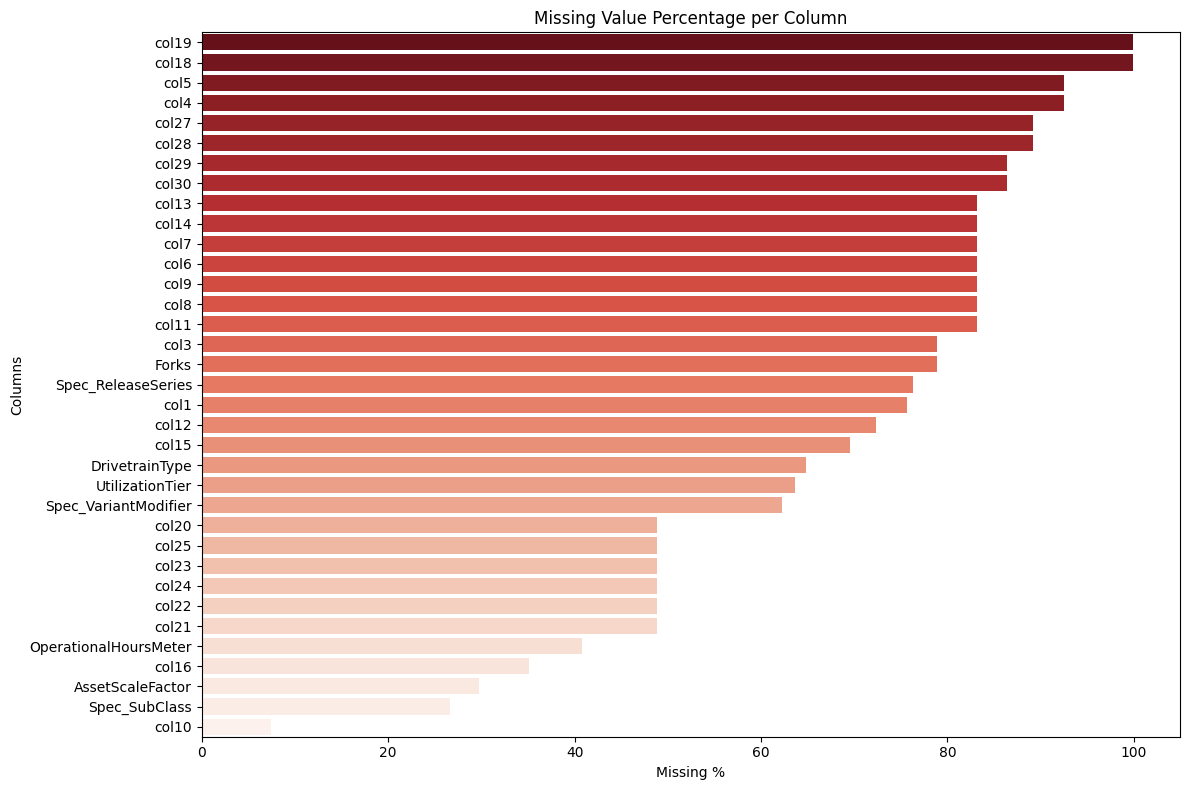

In [38]:
#Missing Value Analysis
null_count = train_raw.isnull().sum()
null_pct   = (null_count / len(train_raw) * 100).round(2)

null_df = pd.DataFrame({
    'Missing Count': null_count,
    'Missing %'    : null_pct
}).sort_values('Missing %', ascending=False)

print(null_df[null_df['Missing Count'] > 0])

#Visualisation
plt.figure(figsize=(12, 8))
sns.barplot(
    x=null_df[null_df['Missing Count'] > 0]['Missing %'],
    y=null_df[null_df['Missing Count'] > 0].index,
    hue=null_df[null_df['Missing Count'] > 0].index,
    palette='Reds_r',
    legend=False
)
plt.title('Missing Value Percentage per Column')
plt.xlabel('Missing %')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()

TargetValue Statistics:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

Null count in TargetValue: 0
Skewness : 0.9700
Kurtosis : 0.4239

Shapiro-Wilk Test (sample of 2000):
 Test Statistic : 0.9168
  p-value   : 0.000000
  Normal Distribution?   : No, the distribution is not normal


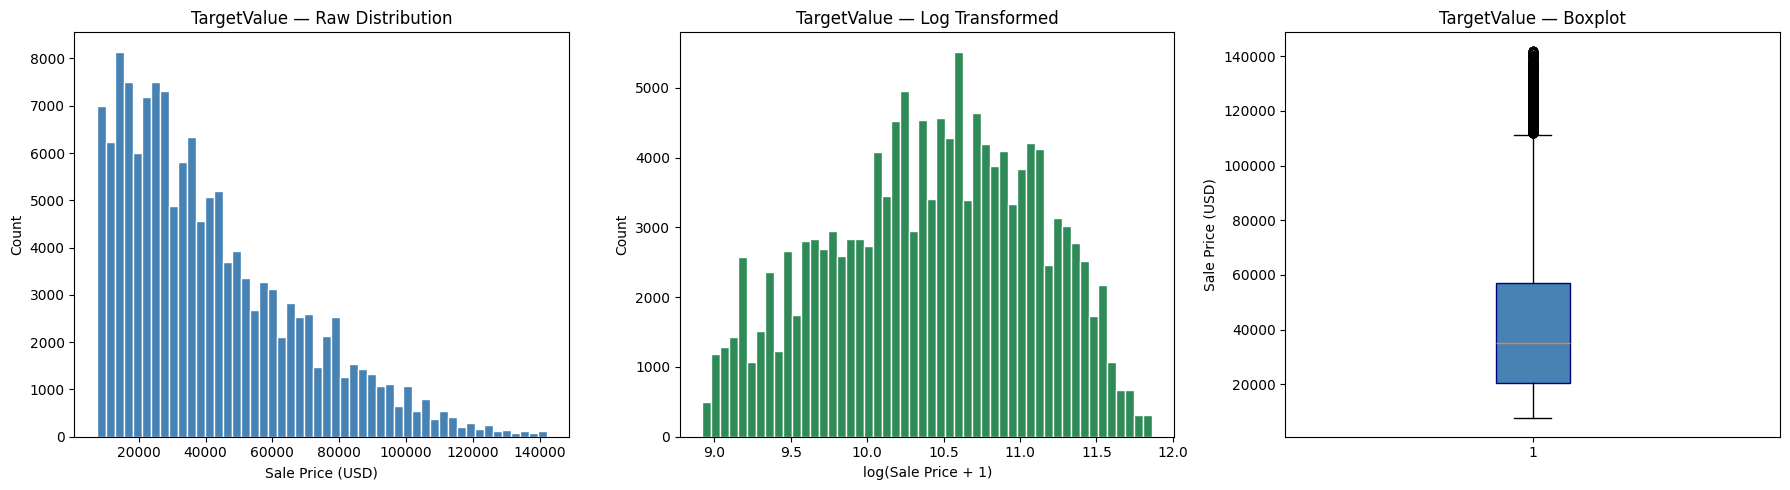

In [39]:
#Target Variable Analysis 
print("TargetValue Statistics:")
print(train_raw['TargetValue'].describe())
print(f"\nNull count in TargetValue: {train_raw['TargetValue'].isnull().sum()}")
print(f"Skewness : {train_raw['TargetValue'].skew():.4f}")
print(f"Kurtosis : {train_raw['TargetValue'].kurt():.4f}")

#Normality Test
sample = train_raw['TargetValue'].dropna().sample(2000, random_state=99)
stat, p_value = stats.shapiro(sample)

print(f"\nShapiro-Wilk Test (sample of 2000):")
print(f" Test Statistic : {stat:.4f}")
print(f"  p-value   : {p_value:.6f}")
print(f"  Normal Distribution?   : {'Yes' if p_value > 0.05 else 'No, the distribution is not normal'}")

#Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw distribution
axes[0].hist(train_raw['TargetValue'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('TargetValue — Raw Distribution')
axes[0].set_xlabel('Sale Price (USD)')
axes[0].set_ylabel('Count')

# Log-transformed distribution
axes[1].hist(np.log1p(train_raw['TargetValue']), bins=50, color='seagreen', edgecolor='white')
axes[1].set_title('TargetValue — Log Transformed')
axes[1].set_xlabel('log(Sale Price + 1)')
axes[1].set_ylabel('Count')

# Boxplot
axes[2].boxplot(train_raw['TargetValue'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='navy'))
axes[2].set_title('TargetValue — Boxplot')
axes[2].set_ylabel('Sale Price (USD)')

plt.tight_layout()
plt.show()

In [40]:
print("-" * 55)
print("DATASET SUMMARY")
print("-" * 55)
print(f"Rows                    : {train_raw.shape[0]:,}")
print(f"Columns                 : {train_raw.shape[1]}")
print(f"Numeric columns         : {train_raw.select_dtypes(include='number').shape[1]}")
print(f"Categorical columns     : {train_raw.select_dtypes(include='object').shape[1]}")
print(f"Total null values       : {train_raw.isnull().sum().sum():,}")
print(f"Duplicate rows          : {train_raw.duplicated().sum()}")
print(f"\nTargetValue")
print(f"  Min                   : ${train_raw['TargetValue'].min():,.0f}")
print(f"  Median                : ${train_raw['TargetValue'].median():,.0f}")
print(f"  Mean                  : ${train_raw['TargetValue'].mean():,.0f}")
print(f"  Max                   : ${train_raw['TargetValue'].max():,.0f}")
print(f"  Skewness              : {train_raw['TargetValue'].skew():,.4f}")
print(f"\nManufactureYear = 1001  : {(train_raw['ManufactureYear'] == 1001).sum():,} rows")
print(f"OperationalHours nulls  : {train_raw['OperationalHoursMeter'].isnull().sum():,} rows")
print(f"Columns ~100% null       : col18, col19")
print(f"\nEquipment types         : {train_raw['InventoryGroupDescription'].nunique()}")
print(f"Regions                 : {train_raw['RegionCode'].nunique()}")
print(f"Unique machine models   : {train_raw['Spec_FullDescriptor'].nunique():,}")

-------------------------------------------------------
DATASET SUMMARY
-------------------------------------------------------
Rows                    : 138,701
Columns                 : 50
Numeric columns         : 6
Categorical columns     : 44
Total null values       : 3,319,054
Duplicate rows          : 0

TargetValue
  Min                   : $7,500
  Median                : $35,000
  Mean                  : $41,522
  Max                   : $142,000
  Skewness              : 0.9700

ManufactureYear = 1001  : 14,719 rows
OperationalHours nulls  : 56,643 rows
Columns ~100% null       : col18, col19

Equipment types         : 6
Regions                 : 53
Unique machine models   : 3,505


### Key Findings

**Dataset Size**
- Training set: **138,701 rows × 50 columns**
- Test set: **15,000 rows × 49 columns** 

**Data Types**
- The dataset contains a mix of numeric (`int64`, `float64`) and categorical (`object`) columns
- `TransactionDate` is read as an `object` (string) — it must be parsed into a proper datetime before we can extract year, month, and quarter from it

**Missing Values**
- `col18` and `col19` are **approx. 100% null** — can be dropped entirely
- Config columns `col4`–`col30` are **80–92% null** — will be filled with the string `"missing"` to preserve information
- `OperationalHoursMeter` is **40.84% null** — will be filled with median 
- `UtilizationTier` is **63.61% null** — will be filled with `"missing"`
- `TargetValue` has **zero nulls** — no imputation needed 


**Target Variable — TargetValue**
- Contains **zero null values** — no imputation needed for the target
- `mean > median` tells us the distribution is **right-skewed** — a few very expensive machines pull the average upward and needs **log tranformation**

**Data Corruption**
- `ManufactureYear` contains **14,719 rows** with value `1001` — a system placeholder for unknown year
- These will be replaced with `NaN` and filled with the **median** of valid years

**Data Variety**
- **6** distinct equipment types (`InventoryGroupDescription`)
- **53** unique regions (`RegionCode`)
- **3,505** unique machine model descriptors (`Spec_FullDescriptor`)

## Phase 2 — Exploratory Data Analysis (EDA)

In [41]:
eda_df = train_raw.copy()

eda_df['TransactionDate'] = pd.to_datetime(eda_df['TransactionDate'])

eda_df['sale_year']      = eda_df['TransactionDate'].dt.year
eda_df['sale_month']     = eda_df['TransactionDate'].dt.month
eda_df['sale_dayofweek'] = eda_df['TransactionDate'].dt.dayofweek 

print(f"EDA copy created — shape: {eda_df.shape}")
print(f"Date range: {eda_df['TransactionDate'].min()} → {eda_df['TransactionDate'].max()}")

EDA copy created — shape: (138701, 53)
Date range: 1990-01-31 00:00:00 → 2013-04-28 00:00:00


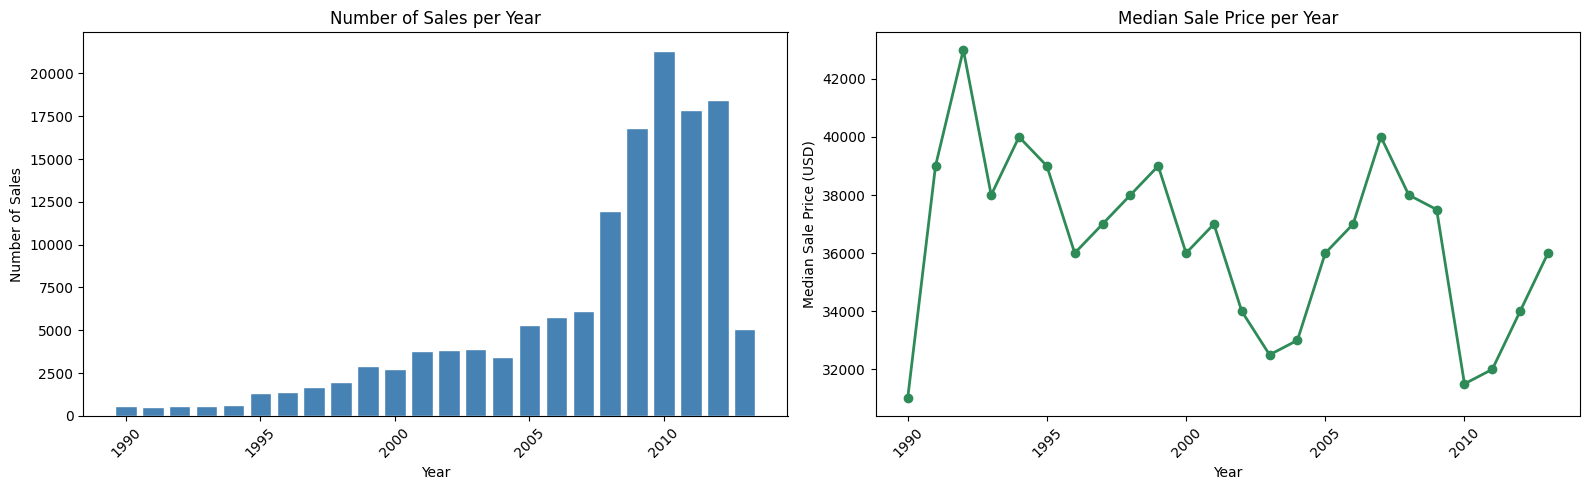

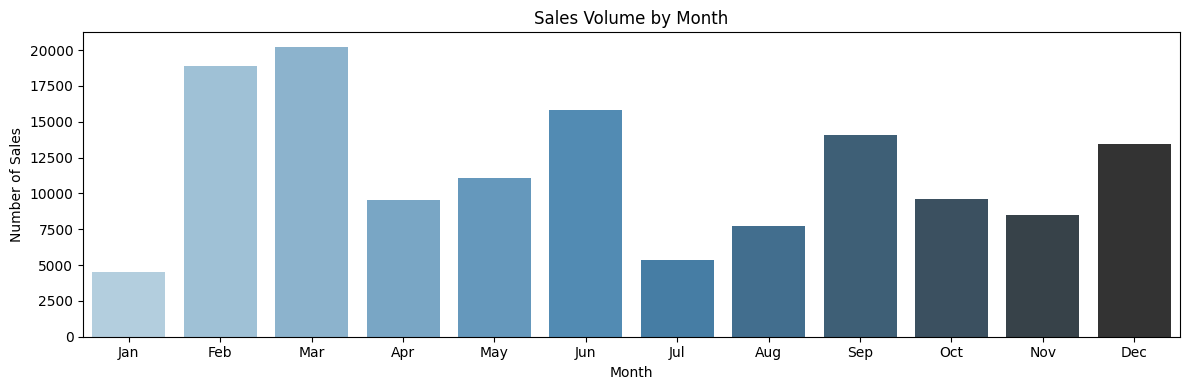

In [42]:
#Sales Trends Over Time
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#Sales per year
yearly_sales = eda_df.groupby('sale_year').size()

axes[0].bar(yearly_sales.index, yearly_sales.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Number of Sales per Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Sales')
axes[0].tick_params(axis='x', rotation=45)

#Median price per year
yearly_price = eda_df.groupby('sale_year')['TargetValue'].median()

axes[1].plot(yearly_price.index, yearly_price.values,
             marker='o', color='seagreen', linewidth=2)
axes[1].set_title('Median Sale Price per Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Median Sale Price (USD)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#Sales Volume by Month
plt.figure(figsize=(12, 4))
monthly_sales = eda_df.groupby('sale_month').size()

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    hue=monthly_sales.index,
    palette='Blues_d',
    legend=False
)
plt.title('Sales Volume by Month')
plt.xlabel('Month')
plt.ylabel('Number of Sales')
plt.xticks(
    ticks=range(12),
    labels=['Jan','Feb','Mar','Apr','May','Jun',
            'Jul','Aug','Sep','Oct','Nov','Dec']
)
plt.tight_layout()
plt.show()

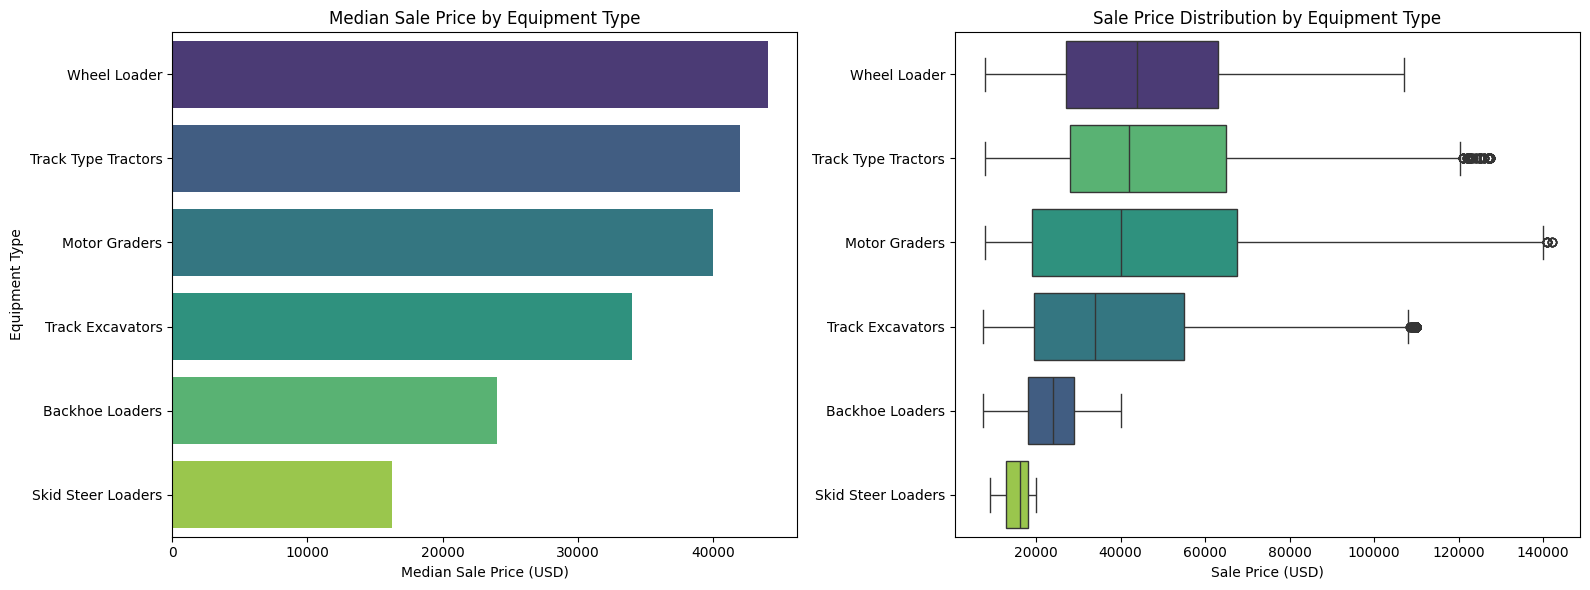

                           count   median     mean      std
InventoryGroupDescription                                  
Wheel Loader               18872  44000.0  46469.0  23913.0
Track Type Tractors        14959  42000.0  48734.0  27343.0
Motor Graders              23405  40000.0  47722.0  33066.0
Track Excavators           71018  34000.0  39281.0  24422.0
Backhoe Loaders            10381  24000.0  23650.0   7658.0
Skid Steer Loaders            66  16250.0  15602.0   2855.0


In [43]:
#Price by Equipment Type
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#Median Price by equipment type
cat_price = (eda_df.groupby('InventoryGroupDescription')['TargetValue']
             .median()
             .sort_values(ascending=False))

sns.barplot(
    x=cat_price.values,
    y=cat_price.index,
    hue=cat_price.index,
    palette='viridis',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Median Sale Price by Equipment Type')
axes[0].set_xlabel('Median Sale Price (USD)')
axes[0].set_ylabel('Equipment Type')

#Price distribution per equipment type
order = (eda_df.groupby('InventoryGroupDescription')['TargetValue']
         .median()
         .sort_values(ascending=False)
         .index)

sns.boxplot(
    data=eda_df,
    x='TargetValue',
    y='InventoryGroupDescription',
    order=order,
    hue='InventoryGroupDescription',
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Sale Price Distribution by Equipment Type')
axes[1].set_xlabel('Sale Price (USD)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(eda_df.groupby('InventoryGroupDescription')['TargetValue']
      .agg(['count', 'median', 'mean', 'std'])
      .sort_values('median', ascending=False)
      .round(0))

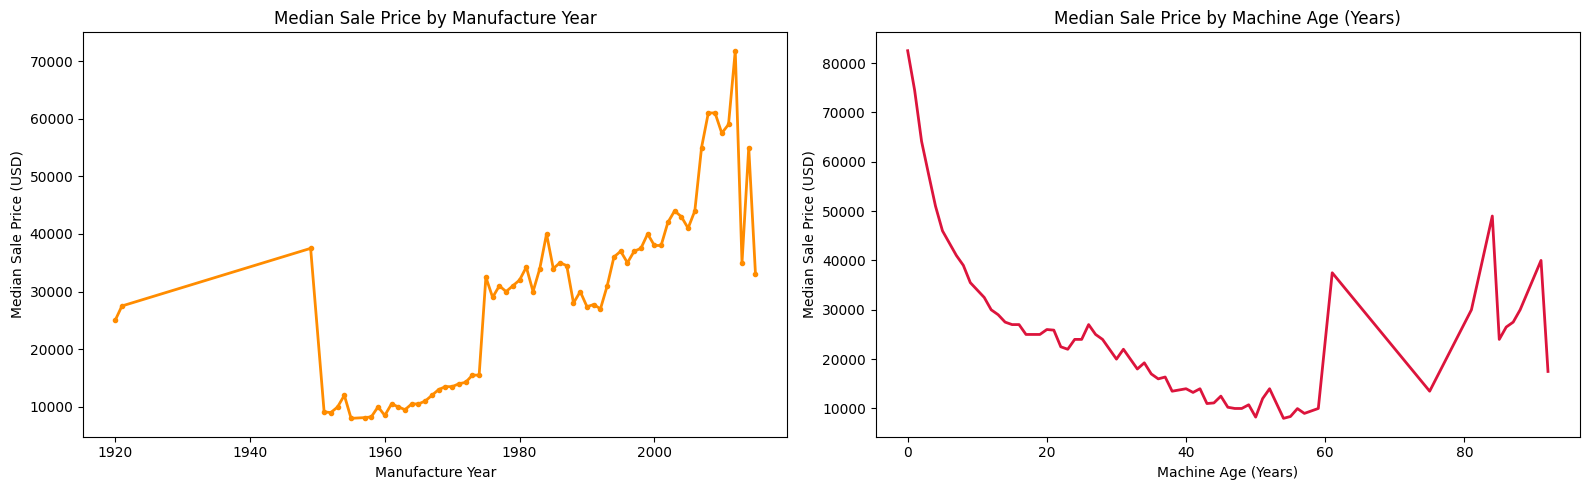

Pearson Correlation (machine_age vs TargetValue): -0.3494
p-value                                         : 0.000000
Statistically significant?                      : Yes

Spearman Correlation (machine_age vs TargetValue): -0.3836
p-value                                          : 0.000000
Statistically significant?                       : Yes


In [44]:
#Price vs ManufactureYear and Machine Age
eda_clean = eda_df[eda_df['ManufactureYear'] != 1001].copy()

#Calculate Machine Age
eda_clean['machine_age'] = eda_clean['sale_year'] - eda_clean['ManufactureYear']
eda_clean_valid = eda_clean[eda_clean['machine_age'] >= 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#Median price by ManufactureYear
year_price = eda_clean.groupby('ManufactureYear')['TargetValue'].median()

axes[0].plot(year_price.index, year_price.values,
             color='darkorange', linewidth=2, marker='o', markersize=3)
axes[0].set_title('Median Sale Price by Manufacture Year')
axes[0].set_xlabel('Manufacture Year')
axes[0].set_ylabel('Median Sale Price (USD)')

#Median price by machine age
age_price = eda_clean_valid.groupby('machine_age')['TargetValue'].median()

axes[1].plot(age_price.index, age_price.values,
             color='crimson', linewidth=2)
axes[1].set_title('Median Sale Price by Machine Age (Years)')
axes[1].set_xlabel('Machine Age (Years)')
axes[1].set_ylabel('Median Sale Price (USD)')
plt.tight_layout()
plt.show()

#Pearson Correlation
corr, pval = stats.pearsonr(
    eda_clean_valid['machine_age'],
    eda_clean_valid['TargetValue']
)
print(f"Pearson Correlation (machine_age vs TargetValue): {corr:.4f}")
print(f"p-value                                         : {pval:.6f}")
print(f"Statistically significant?                      : {'Yes' if pval < 0.05 else 'No'}")

# Spearman Correlation
spearman_corr, spearman_pval = stats.spearmanr(
    eda_clean_valid['machine_age'],
    eda_clean_valid['TargetValue']
)
print(f"\nSpearman Correlation (machine_age vs TargetValue): {spearman_corr:.4f}")
print(f"p-value                                          : {spearman_pval:.6f}")
print(f"Statistically significant?                       : {'Yes' if spearman_pval < 0.05 else 'No'}")

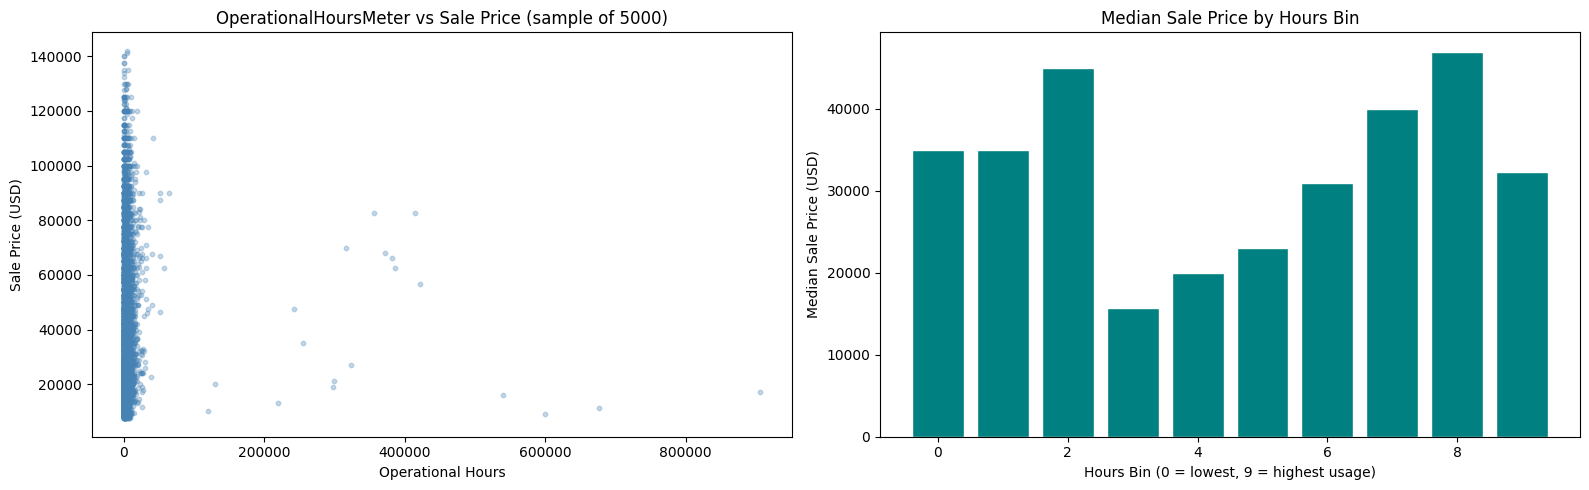

Pearson Correlation  : 0.0020 (p-value: 0.567945)
Spearman Correlation : 0.0423 (p-value: 0.000000)


In [45]:
#Price vs OperationalHoursMeter
eda_hours = eda_df[eda_df['OperationalHoursMeter'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sample_hours = eda_hours.sample(5000, random_state=99)

axes[0].scatter(
    sample_hours['OperationalHoursMeter'],
    sample_hours['TargetValue'],
    alpha=0.3,
    color='steelblue',
    s=10
)
axes[0].set_title('OperationalHoursMeter vs Sale Price (sample of 5000)')
axes[0].set_xlabel('Operational Hours')
axes[0].set_ylabel('Sale Price (USD)')

eda_hours['hours_bin'] = pd.cut(
    eda_hours['OperationalHoursMeter'],
    bins=10,
    labels=False
)
bin_price = eda_hours.groupby('hours_bin')['TargetValue'].median()

axes[1].bar(bin_price.index, bin_price.values,
            color='teal', edgecolor='white')
axes[1].set_title('Median Sale Price by Hours Bin')
axes[1].set_xlabel('Hours Bin (0 = lowest, 9 = highest usage)')
axes[1].set_ylabel('Median Sale Price (USD)')

plt.tight_layout()
plt.show()

#Person Correlation
pearson_corr, pearson_pval = stats.pearsonr(
    eda_hours['OperationalHoursMeter'],
    eda_hours['TargetValue']
)
print(f"Pearson Correlation  : {pearson_corr:.4f} (p-value: {pearson_pval:.6f})")

#Spearman Correlation
spearman_corr, spearman_pval = stats.spearmanr(
    eda_hours['OperationalHoursMeter'],
    eda_hours['TargetValue']
)
print(f"Spearman Correlation : {spearman_corr:.4f} (p-value: {spearman_pval:.6f})")

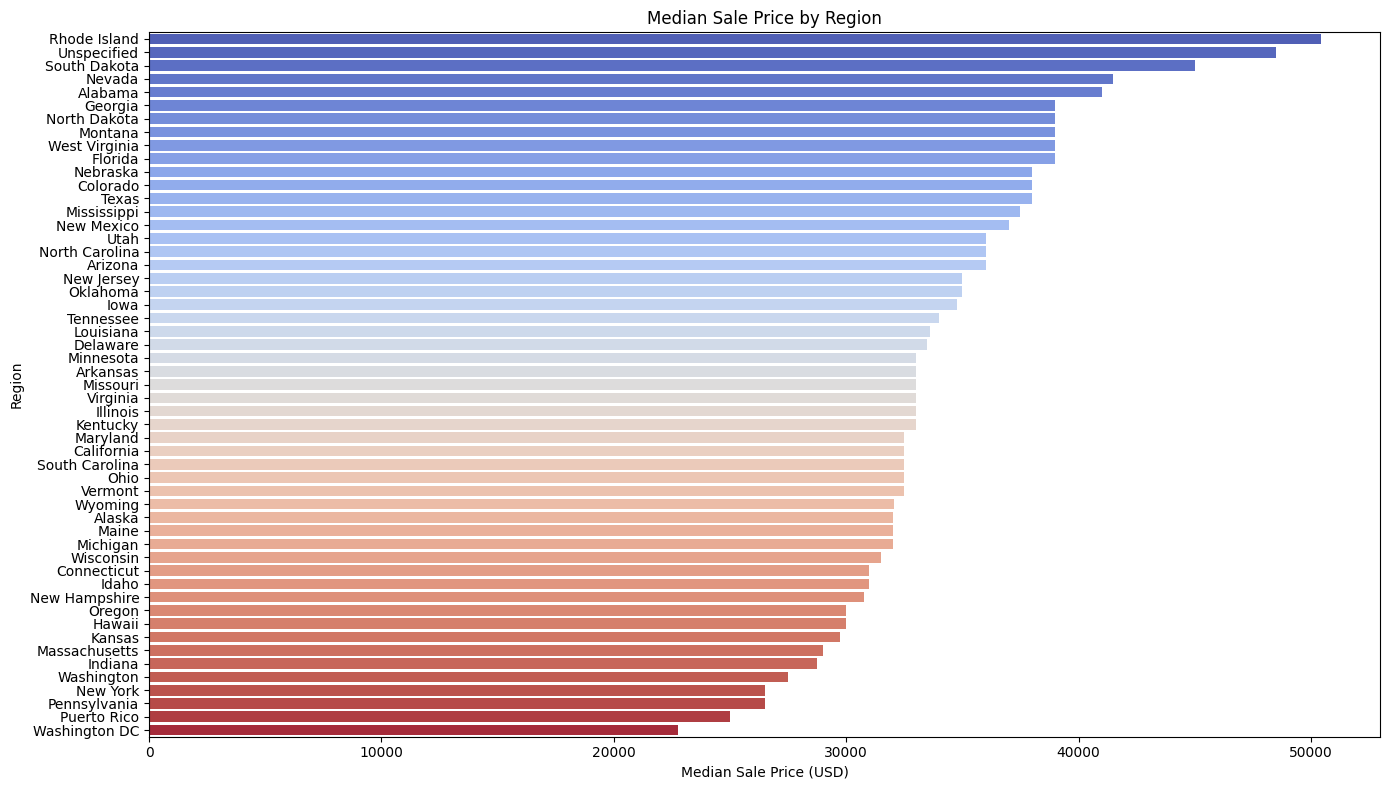

Region with highest median price : Rhode Island
Region with lowest median price  : Washington DC
Price range across regions       : $22,750 — $50,450


In [46]:
#Price by Region
plt.figure(figsize=(14, 8))

region_price = (eda_df.groupby('RegionCode')['TargetValue']
                .median()
                .sort_values(ascending=False))

sns.barplot(
    x=region_price.values,
    y=region_price.index,
    hue=region_price.index,
    palette='coolwarm',
    legend=False
)
plt.title('Median Sale Price by Region')
plt.xlabel('Median Sale Price (USD)')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

print(f"Region with highest median price : {region_price.idxmax()}")
print(f"Region with lowest median price  : {region_price.idxmin()}")
print(f"Price range across regions       : ${region_price.min():,.0f} — ${region_price.max():,.0f}")

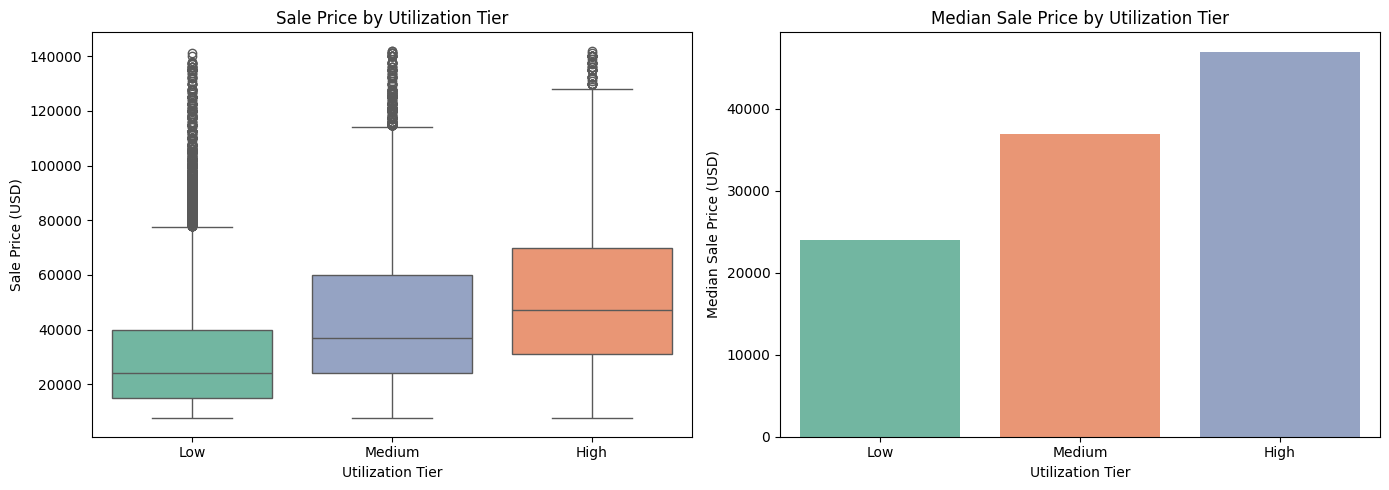

One-Way ANOVA Test:
  F-statistic : 2126.3447
  p-value     : 0.000000
  Significant difference across tiers? Yes — price differs by utilization tier


In [47]:
#Price by Utilization 
eda_util = eda_df[eda_df['UtilizationTier'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ['Low', 'Medium', 'High']

sns.boxplot(
    data=eda_util,
    x='UtilizationTier',
    y='TargetValue',
    order=order,
    hue='UtilizationTier',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Sale Price by Utilization Tier')
axes[0].set_xlabel('Utilization Tier')
axes[0].set_ylabel('Sale Price (USD)')


tier_price = (eda_util.groupby('UtilizationTier')['TargetValue']
              .median()
              .reindex(order))

sns.barplot(
    x=tier_price.index,
    y=tier_price.values,
    hue=tier_price.index,
    palette='Set2',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Median Sale Price by Utilization Tier')
axes[1].set_xlabel('Utilization Tier')
axes[1].set_ylabel('Median Sale Price (USD)')

plt.tight_layout()
plt.show()

#One-way ANOVA test
low    = eda_util[eda_util['UtilizationTier'] == 'Low']['TargetValue']
medium = eda_util[eda_util['UtilizationTier'] == 'Medium']['TargetValue']
high   = eda_util[eda_util['UtilizationTier'] == 'High']['TargetValue']

f_stat, p_val = stats.f_oneway(low, medium, high)

print(f"One-Way ANOVA Test:")
print(f"  F-statistic : {f_stat:.4f}")
print(f"  p-value     : {p_val:.6f}")
print(f"  Significant difference across tiers? {'Yes — price differs by utilization tier' if p_val < 0.05 else 'No'}")


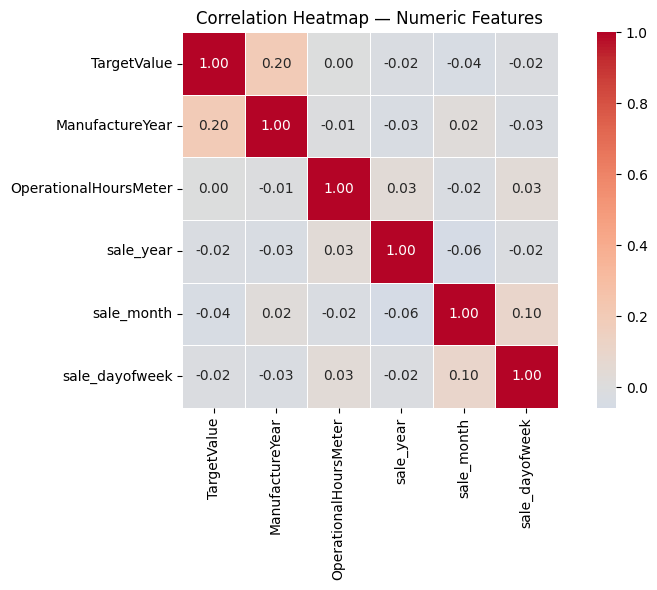

In [48]:
#Correlation Heatmap
numeric_cols = ['TargetValue', 'ManufactureYear', 'OperationalHoursMeter',
                'sale_year', 'sale_month', 'sale_dayofweek']

corr_matrix = eda_df[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr_matrix,
    annot=True,        
    fmt='.2f',         
    cmap='coolwarm',   
    center=0,          
    linewidths=0.5,    
    square=True        
)
plt.title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()

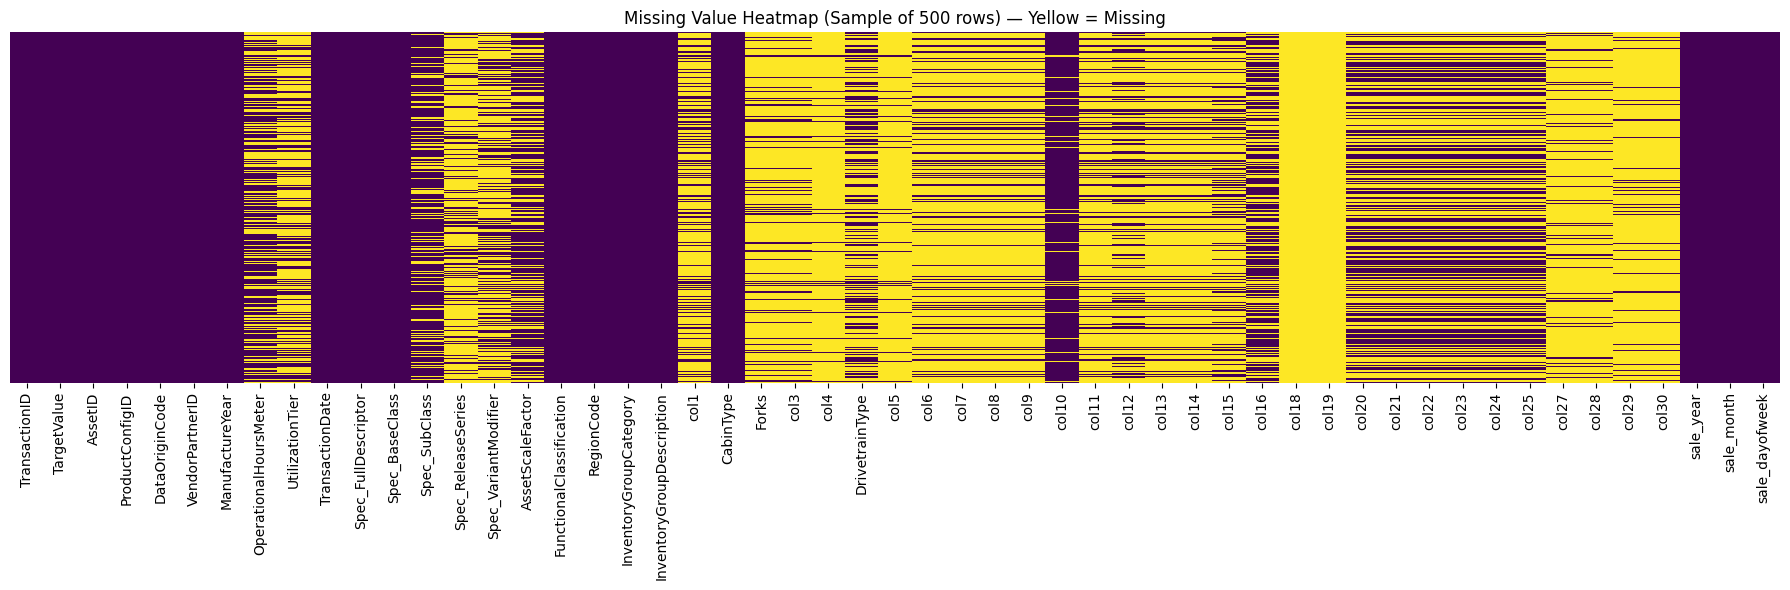

In [49]:
#Missing Value Heatmap
sample_eda = eda_df.sample(500, random_state=99)

plt.figure(figsize=(18, 6))
sns.heatmap(
    sample_eda.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)
plt.title('Missing Value Heatmap (Sample of 500 rows) — Yellow = Missing')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Phase 2 — EDA: Key Insights

**Target Variable**
- TargetValue is right-skewed with positive skewness, confirmed by Shapiro-Wilk (p ≈ 0.000000)
- Log transformation will normalise the distribution before modeling

**Sales Trends Over Time**
- Sales volume peaks in Q1 (January–March) construction projects begin at year start
- Median sale price increases over time due to inflation — `TransactionYear` is a strong feature

**Equipment Type**
- Equipment type (InventoryGroupDescription) strongly influences price
- Track Type Tractors and Wheel Loaders the highest median prices
- Skid Steer Loaders are the most common but lowest-priced category

**Machine Age and Usage**
- Newer machines (higher ManufactureYear) sell for significantly more, clear depreciation trend
- Pearson correlation (machine_age vs TargetValue): **-0.35** — statistically significant (p ≈ 0.000000)
- Both Pearson (0.002) and Spearman (0.042) correlations between OperationalHoursMeter and TargetValue are near zero, not because hours are irrelevant, but because machine type confounds the relationship. Hours only carry signal within the same machine type


**Regional Differences**
- Median prices vary significantly across the 53 regions
- Regional demand, supply, and shipping costs drive these differences

**UtilizationTier**
- One-Way ANOVA confirms price differences across Low, Medium, High tiers are statistically significant (p ≈ 0.000000)
- Despite 63.6% missingness, the column carries real predictive signal

**Missing Value Pattern**
- Missingness is structural not random — config columns are missing together for the same machine types
- Filling with "missing" string preserves this as meaningful information for the model

## Phase 3 — Preprocessing & Feature Engineering

In [3]:
#Column Groups
DROP_COLS = ['col18', 'col19', 'TransactionID', 'AssetID']

NUM_COLS = ['ManufactureYear', 'OperationalHoursMeter']

OHE_COLS = ['RegionCode', 'CabinType', 'UtilizationTier']

HIGH_CARD_COLS = [
    'ProductConfigID', 'DataOriginCode', 'VendorPartnerID',
    'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass',
    'Spec_ReleaseSeries', 'Spec_VariantModifier', 'FunctionalClassification',
    'InventoryGroupCategory', 'InventoryGroupDescription',
    'AssetScaleFactor', 'Forks', 'DrivetrainType',
    'col1', 'col3', 'col4', 'col5', 'col6', 'col7', 'col8',
    'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15',
    'col16', 'col20', 'col21', 'col22', 'col23', 'col24',
    'col25', 'col27', 'col28', 'col29', 'col30'
]

print(f"Columns to drop          : {len(DROP_COLS)}")
print(f"Numerical columns        : {NUM_COLS}")
print(f"OHE columns              : {OHE_COLS}")
print(f"High cardinality columns : {len(HIGH_CARD_COLS)}")

Columns to drop          : 4
Numerical columns        : ['ManufactureYear', 'OperationalHoursMeter']
OHE columns              : ['RegionCode', 'CabinType', 'UtilizationTier']
High cardinality columns : 39


In [4]:
# Preprocessing function
def preprocess(df, is_train=True, median_year=None, median_hours=None):
    df = df.copy()

    #Drop columns
    df.drop(columns=[c for c in DROP_COLS if c in df.columns], inplace=True)

    #Parse TransactionDate
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

    #Fix corrupt ManufactureYear
    df['ManufactureYear'] = df['ManufactureYear'].replace(1001, np.nan)
    if is_train:
        median_year = df['ManufactureYear'].median()
    df['ManufactureYear'] = df['ManufactureYear'].fillna(median_year)

    #Binary flags before imputation
    df['HasOperationalHours'] = df['OperationalHoursMeter'].notna().astype(int)
    df['HasVariantModifier']  = df['Spec_VariantModifier'].notna().astype(int)

    #Fill OperationalHoursMeter nulls with median from train
    if is_train:
        median_hours = df['OperationalHoursMeter'].median()
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].fillna(median_hours)

    #Fill categorical nulls with 'missing'
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].fillna('missing')

    #Feature Engineering
    df['TransactionYear']    = df['TransactionDate'].dt.year
    df['TransactionMonth']   = df['TransactionDate'].dt.month
    df['TransactionQuarter'] = df['TransactionDate'].dt.quarter

    # AssetAge — how old the machine was at time of sale
    df['AssetAge'] = (df['TransactionYear'] - df['ManufactureYear']).clip(lower=0)

    # DescriptorLength — character count of model name
    df['DescriptorLength'] = df['Spec_FullDescriptor'].apply(len)

    # ManufactureDecade — groups machines by decade of manufacture
    df['ManufactureDecade'] = (df['ManufactureYear'] // 10) * 10

    # SpecificationComplexity — word count of model name
    df['SpecificationComplexity'] = df['Spec_FullDescriptor'].apply(
        lambda x: len(str(x).split())
    )

    # HoursPerYear — usage intensity (hours per year of age)
    df['HoursPerYear'] = (
        df['OperationalHoursMeter'] / (df['AssetAge'] + 1)
    ).fillna(0).replace([np.inf, -np.inf], 0)

    #Drop TransactionDate
    df.drop(columns=['TransactionDate'], inplace=True)

    return df, median_year, median_hours

In [5]:
#Label Encoding
def label_encode(train_df, test_df=None):

    train_df = train_df.copy()
    if test_df is not None:
        test_df = test_df.copy()

    label_encoders = {}

    for col in HIGH_CARD_COLS:

        if col not in train_df.columns:
            continue

        le = LabelEncoder()
        train_df[col] = le.fit_transform(train_df[col].astype(str))
        label_encoders[col] = le

        if test_df is not None and col in test_df.columns:

            known = set(le.classes_)

            test_df[col] = test_df[col].astype(str).apply(
                lambda x, le=le: le.transform([x])[0] if x in known else -1
            )

    return train_df, test_df, label_encoders

In [6]:
#Pipeline
def build_pipeline():

    #Numerical
    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ])

    #Categorical OHE
    ohe_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    #ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_pipeline, NUM_COLS),
            ('ohe', ohe_pipeline, OHE_COLS)
        ],
        remainder='passthrough'
    )

    return preprocessor

In [7]:
# Apply preprocessing pipeline to train and test
test_ids = test_raw['TransactionID'].copy()

#Preprocess
train_df, median_year, median_hours = preprocess(train_raw, is_train=True)
test_df, _, _ = preprocess(
    test_raw,
    is_train=False,
    median_year=median_year,
    median_hours=median_hours
)
print(f"After preprocess — Train: {train_df.shape} | Test: {test_df.shape}")

#Label encode high cardinality columns
train_df, test_df, label_encoders = label_encode(train_df, test_df)
print(f"After label encoding — Train: {train_df.shape} | Test: {test_df.shape}")

#Separate target before pipeline and log transform
y_full   = np.log1p(train_df['TargetValue'])
train_df = train_df.drop(columns=['TargetValue'])

#Build and fit ColumnTransformer pipeline
preprocessor    = build_pipeline()
train_processed = preprocessor.fit_transform(train_df)
test_processed  = preprocessor.transform(test_df)

#Convert back to DataFrame with correct column names
ohe_cols_out = (preprocessor
                .named_transformers_['ohe']
                .named_steps['ohe']
                .get_feature_names_out(OHE_COLS)
                .tolist())

passthrough_cols = [c for c in train_df.columns
                    if c not in NUM_COLS and c not in OHE_COLS]

all_cols_out = NUM_COLS + ohe_cols_out + passthrough_cols

train_df = pd.DataFrame(train_processed, columns=all_cols_out)
test_df  = pd.DataFrame(test_processed,  columns=all_cols_out)

print(f"After pipeline — Train: {train_df.shape} | Test: {test_df.shape}")

After preprocess — Train: (138701, 55) | Test: (15000, 54)
After label encoding — Train: (138701, 55) | Test: (15000, 54)
After pipeline — Train: (138701, 111) | Test: (15000, 111)


### Phase 3 — Preprocessing Decisions Summary

| Step | Tool Used | Decision | Reason |
|---|---|---|---|
| Drop col18, col19, TransactionID, AssetID | pandas | Remove entirely | 100% null / row identifier / no predictive value |
| ManufactureYear 1001 → NaN | pandas | Replace then fill with median | Corrupt placeholder — 14,719 rows affected |
| Binary flags before imputation | pandas | HasOperationalHours, HasVariantModifier | Missingness itself is predictive signal |
| Numeric imputation | SimpleImputer (median) | Fill with median | Robust to outliers and skew |
| Categorical imputation | SimpleImputer (constant) | Fill with 'missing' | Structural missingness is meaningful |
| Numerical scaling | StandardScaler | Mean=0, Std=1 | Prevents large-scale features dominating |
| OHE encoding | OneHotEncoder | Binary columns per category | Low cardinality — 3 unique values each |
| High cardinality encoding | LabelEncoder | Integer mapping | OHE would create 3500+ columns |
| Pipeline | sklearn Pipeline | Chain imputer + scaler/encoder | Guarantees correct step order |
| ColumnTransformer | sklearn ColumnTransformer | Apply different pipelines per column group | Single reusable object — no leakage |
| Fit on train only | All transformers | Apply learned stats to test | Core leakage prevention principle |
| Log transform target | np.log1p | Normalise TargetValue | Right-skewed target hurts regression models |
| Feature Engineering | pandas | 8 new features created | Capture depreciation, seasonality, usage intensity |

In [8]:
# Train/Validation Split
X = train_df.copy()
y = y_full.copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"X_train shape : {X_train.shape}")
print(f"X_val shape   : {X_val.shape}")
print(f"y_train shape : {y_train.shape}")
print(f"y_val shape   : {y_val.shape}")

X_train shape : (110960, 111)
X_val shape   : (27741, 111)
y_train shape : (110960,)
y_val shape   : (27741,)


### Phase 3 Complete — Data is Model-Ready

| Dataset | Shape | Contents |
|---|---|---|
| X_train | (110960, 111) | All features are processed, encoded, scaled |
| X_val | (27741, 111) | Same structure that model never sees this during training |
| y_train | (110960,) | log(TargetValue + 1) for training rows |
| y_val | (27741,) | log(TargetValue + 1) for validation rows |
| test_df | (15000, 111) |Same pipeline applied to competition test set|

**8 Engineered Features + 2 Binary Flags Created:**

| Feature | Created From | Purpose |
|---|---|---|
| TransactionYear | TransactionDate | Captures inflation trend over time |
| TransactionMonth | TransactionDate | Captures seasonal auction patterns |
| TransactionQuarter | TransactionDate | Captures business cycle patterns |
| AssetAge | TransactionYear - ManufactureYear | Depreciation signal — more informative than year alone |
| DescriptorLength | Spec_FullDescriptor | Character count — proxy for machine complexity |
| ManufactureDecade | ManufactureYear | Groups machines by technology generation |
| SpecificationComplexity | Spec_FullDescriptor | Word count — alternative complexity measure |
| HoursPerYear | OperationalHoursMeter / AssetAge | Usage intensity — captures wear rate not just total hours |
| HasOperationalHours | OperationalHoursMeter | Binary — missingness of hours is itself informative |
| HasVariantModifier | Spec_VariantModifier | Binary — presence of custom variant is informative |

## Phase 4 — Model Building & Hyperparameter Tuning

In [9]:
# RMSLE Evaluation Function
def rmsle(y_true, y_pred):

    y_pred_clipped = np.clip(y_pred, 0, None)
    return np.sqrt(mean_squared_error(y_true, y_pred_clipped))

print("RMSLE function defined.")

RMSLE function defined.


In [10]:
#Baseline Model 

baseline_pred  = np.full(len(y_val), y_train.median())
baseline_score = rmsle(y_val, baseline_pred)

print(f"Baseline (Median) RMSLE: {baseline_score:.4f}")

Baseline (Median) RMSLE: 0.6707


In [11]:
#Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred  = lr.predict(X_val)
lr_score = rmsle(y_val, lr_pred)

print(f"Linear Regression RMSLE: {lr_score:.4f}")

Linear Regression RMSLE: 0.4463


In [12]:
#Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=7,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred  = rf.predict(X_val)
rf_score = rmsle(y_val, rf_pred)

print(f"Random Forest RMSLE: {rf_score:.4f}")

Random Forest RMSLE: 0.2458


In [13]:
#XGBoost
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=13,
    n_jobs=-1,
    verbosity=0
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_pred  = xgb.predict(X_val)
xgb_score = rmsle(y_val, xgb_pred)

print(f"XGBoost RMSLE: {xgb_score:.4f}")

XGBoost RMSLE: 0.2302


In [14]:
#LightGBM
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=21,
    n_jobs=-1,
    verbose=-1
)

lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)]
)

lgbm_pred  = lgbm.predict(X_val)
lgbm_score = rmsle(y_val, lgbm_pred)

print(f"LightGBM RMSLE: {lgbm_score:.4f}")

LightGBM RMSLE: 0.2229


In [15]:
#CatBoost
cat = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=0
)

cat.fit(
    X_train, y_train,
    eval_set=(X_val, y_val)
)

cat_pred  = cat.predict(X_val)
cat_score = rmsle(y_val, cat_pred)

print(f"CatBoost RMSLE: {cat_score:.4f}")

CatBoost RMSLE: 0.2555


### Base Model Results Summary

| Model | RMSLE | Key Insight |
|---|---|---|
| Baseline | 0.6707 | Floor — predicting median for every row |
| Linear Regression | 0.4463 | Limited by linearity assumption |
| CatBoost | 0.2553 | Categorical advantage bypassed by pre-encoding |
| Random Forest | 0.2458 | Non-linearity captured but bagging less focused |
| XGBoost | 0.2302 | Sequential correction improves over bagging |
| LightGBM | 0.2225 | Best — leaf-wise growth most efficient |

### Hyperparameter Tuning

In [17]:
#Manual Hyperparameter Tuning
lgbm_tuned = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.02,
    max_depth=10,
    num_leaves=127,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_samples=20,
    random_state=21,
    n_jobs=-1,
    verbose=-1
)

lgbm_tuned.fit(X_train, y_train, eval_set=[(X_val, y_val)])

lgbm_tuned_pred  = lgbm_tuned.predict(X_val)
lgbm_tuned_score = rmsle(y_val, lgbm_tuned_pred)

print(f"Manual Tuned LightGBM RMSLE: {lgbm_tuned_score:.4f}")

Manual Tuned LightGBM RMSLE: 0.2155


In [18]:
#RandomizedSearchCV
param_dist = {
    'n_estimators'     : [300, 500, 1000],
    'learning_rate'    : [0.02, 0.05],
    'max_depth'        : [6, 8, 10],
    'num_leaves'       : [63, 127],
    'min_child_samples': [10, 20]
}

lgbm_random = LGBMRegressor(
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=21,
    n_jobs=1,
    verbose=-1,
)

random_search = RandomizedSearchCV(
    estimator=lgbm_random,
    param_distributions=param_dist,
    n_iter=10,
    scoring='neg_root_mean_squared_error',
    cv=2,
    random_state=21,
    n_jobs=-1,
    verbose=0
)

random_search.fit(X_train, y_train)

print("RandomizedSearchCV — Best Parameters:")
print(random_search.best_params_)
print(f"Best CV RMSLE : {-random_search.best_score_:.4f}")

lgbm_random_best = random_search.best_estimator_
random_pred      = lgbm_random_best.predict(X_val)
random_score     = rmsle(y_val, random_pred)
print(f"RandomizedSearch LightGBM RMSLE: {random_score:.4f}")

RandomizedSearchCV — Best Parameters:
{'num_leaves': 127, 'n_estimators': 1000, 'min_child_samples': 10, 'max_depth': 10, 'learning_rate': 0.02}
Best CV RMSLE : 0.2239
RandomizedSearch LightGBM RMSLE: 0.2149


In [19]:
#GridSearchCV
param_grid = {
    'n_estimators'     : [500, 1000],
    'learning_rate'    : [0.02, 0.05],
    'max_depth'        : [8, 10],
    'num_leaves'       : [63, 127],
    'min_child_samples': [10, 20]
}

lgbm_grid = LGBMRegressor(
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=21,
    n_jobs=1,
    verbose=-1,
)

grid_search = GridSearchCV(
    estimator=lgbm_grid,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=2,
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

print("GridSearchCV — Best Parameters:")
print(grid_search.best_params_)
print(f"Best CV RMSLE : {-grid_search.best_score_:.4f}")

lgbm_grid_best = grid_search.best_estimator_
grid_pred      = lgbm_grid_best.predict(X_val)
grid_score     = rmsle(y_val, grid_pred)
print(f"GridSearch LightGBM RMSLE: {grid_score:.4f}")

GridSearchCV — Best Parameters:
{'learning_rate': 0.05, 'max_depth': 10, 'min_child_samples': 10, 'n_estimators': 1000, 'num_leaves': 127}
Best CV RMSLE : 0.2187
GridSearch LightGBM RMSLE: 0.2072


In [20]:
## GridSearchCV Extended — Wider Parameter Range
param_grid_extended = {
    'learning_rate'    : [0.01, 0.02],
    'max_depth'        : [12, 14],
    'num_leaves'       : [255, 512],
    'min_child_samples': [5, 10],
    'subsample'        : [0.7, 0.8],
}

lgbm_extended = LGBMRegressor(
    n_estimators=1000,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=21,
    n_jobs=1,
    verbose=-1
)

grid_search_extended = GridSearchCV(
    estimator=lgbm_extended,
    param_grid=param_grid_extended,
    scoring='neg_root_mean_squared_error',
    cv=2,
    n_jobs=-1,
    verbose=0
)

grid_search_extended.fit(X_train, y_train)

print("GridSearch Extended — Best Parameters:")
print(grid_search_extended.best_params_)
print(f"Best CV RMSLE : {-grid_search_extended.best_score_:.4f}")

lgbm_extended_best = grid_search_extended.best_estimator_
extended_pred      = lgbm_extended_best.predict(X_val)
extended_score     = rmsle(y_val, extended_pred)
print(f"Extended GridSearch RMSLE: {extended_score:.4f}")

GridSearch Extended — Best Parameters:
{'learning_rate': 0.02, 'max_depth': 14, 'min_child_samples': 5, 'num_leaves': 512, 'subsample': 0.7}
Best CV RMSLE : 0.2176
Extended GridSearch RMSLE: 0.2041


### Hyperparameter Tuning Summary

Three levels of tuning applied to LightGBM:

| Approach | Best Params | Val RMSLE |
|---|---|---|
| Manual Tuning | lr=0.02, n_est=1000, depth=10, leaves=127 | 0.2155 |
| RandomizedSearchCV | lr=0.02, n_est=1000, depth=10, leaves=127 | 0.2149 |
| GridSearchCV | lr=0.02, n_est=1000, depth=10, leaves=127 | 0.2072 |
| GridSearch Extended | lr=0.02, depth=14, leaves=512, subsample=0.7 | 0.2041 |

**Key insight:** Each tuning level confirmed the same direction — lower learning rate, deeper trees, more leaves. GridSearch Extended pushed further into that direction discovering deeper params that the initial grid didn't cover.

### Experimentation

In [25]:
# colsample_bytree Experimentation
# colsample_values = [0.3, 0.25, 0.2, 0.15, 0.1]
# colsample_scores = {}
# for col in colsample_values:
#     preds = []
#     for seed in [7, 13, 21, 99, 256]:
#         m = LGBMRegressor(
#             learning_rate=0.02, max_depth=14, min_child_samples=5,
#             n_estimators=2000, num_leaves=512, subsample=0.7,
#             colsample_bytree=col, reg_alpha=0.1, reg_lambda=1.0,
#             random_state=seed, n_jobs=-1, verbose=-1
#         )
#         m.fit(X_train, y_train)
#         preds.append(m.predict(X_val))
#     score = rmsle(y_val, np.mean(preds, axis=0))
#     colsample_scores[col] = score
#     print(f"col={col} → RMSLE: {score:.4f}")

#Results
print("colsample_bytree Sweep:")
print("─" * 45)
colsample_results = {
    0.30 : 0.2034, 
    0.25 : 0.2038,
    0.20 : 0.2045,
    0.15 : 0.2071,
    0.10 : 0.2115,
}
for col, score in colsample_results.items():
    marker = ' : best' if col == 0.30 else ''
    print(f"  colsample={col:.2f} → RMSLE: {score:.4f}{marker}")

colsample_bytree Sweep:
─────────────────────────────────────────────
  colsample=0.30 → RMSLE: 0.2034 : best
  colsample=0.25 → RMSLE: 0.2038
  colsample=0.20 → RMSLE: 0.2045
  colsample=0.15 → RMSLE: 0.2071
  colsample=0.10 → RMSLE: 0.2115


In [27]:
# n_estimators Experimentation
# n_est_scores = {}
# for n_est in [2000, 3000, 4000, 5000, 6000, 7000, 8000]:
#     preds = []
#     for seed in [7, 13, 21, 99, 256]:
#         m = LGBMRegressor(
#             learning_rate=0.02, max_depth=14, min_child_samples=5,
#             n_estimators=n_est, num_leaves=512, subsample=0.7,
#             colsample_bytree=0.3, reg_alpha=0.1, reg_lambda=1.0,
#             random_state=seed, n_jobs=-1, verbose=-1
#         )
#         m.fit(X_train, y_train)
#         preds.append(m.predict(X_val))
#     score = rmsle(y_val, np.mean(preds, axis=0))
#     n_est_scores[n_est] = score
#     print(f"n_estimators={n_est} → RMSLE: {score:.4f}")

#Results
print("n_estimators Sweep Results (colsample=0.3, 5 seeds):")
print("─" * 45)
n_est_results = {
    2000: 0.2034,
    3000: 0.2016,
    4000: 0.2007,
    5000: 0.2002,
    6000: 0.2000,
    7000: 0.1999,  
    8000: 0.1999,
}
for n_est, score in n_est_results.items():
    marker = ' : best' if n_est == 7000 else ''
    print(f"  n_estimators={n_est} → RMSLE: {score:.4f}{marker}")


n_estimators Sweep Results (colsample=0.3, 5 seeds):
─────────────────────────────────────────────
  n_estimators=2000 → RMSLE: 0.2034
  n_estimators=3000 → RMSLE: 0.2016
  n_estimators=4000 → RMSLE: 0.2007
  n_estimators=5000 → RMSLE: 0.2002
  n_estimators=6000 → RMSLE: 0.2000
  n_estimators=7000 → RMSLE: 0.1999 : best
  n_estimators=8000 → RMSLE: 0.1999


In [29]:
# num_leaves Experimentation

# for leaves in [127, 255, 512]:
#     preds = []
#     for seed in [7, 13, 21, 99, 256]:
#         m = LGBMRegressor(
#             learning_rate=0.02, max_depth=14, min_child_samples=5,
#             n_estimators=7000, num_leaves=leaves, subsample=0.7,
#             colsample_bytree=0.3, reg_alpha=0.1, reg_lambda=1.0,
#             random_state=seed, n_jobs=-1, verbose=-1
#         )
#         m.fit(X_train, y_train)
#         preds.append(m.predict(X_val))
#     score = rmsle(y_val, np.mean(preds, axis=0))
#     print(f"num_leaves={leaves} → RMSLE: {score:.4f}")

# Results
print("num_leaves Sweep Results (colsample=0.3, 7000 trees, 5 seeds):")
print("─" * 50)
print("  num_leaves=127 → RMSLE: 0.2015")
print("  num_leaves=255 → RMSLE: 0.1999")
print("  num_leaves=512 → RMSLE: 0.1993  : best")

num_leaves Sweep Results (colsample=0.3, 7000 trees, 5 seeds):
──────────────────────────────────────────────────
  num_leaves=127 → RMSLE: 0.2015
  num_leaves=255 → RMSLE: 0.1999
  num_leaves=512 → RMSLE: 0.1993  : best


### Experimentation Summary

**Step 1 — colsample_bytree sweep**
Tested values from 0.3 down to 0.1 — colsample=0.3 gave best ensemble RMSLE of 0.2034

**Step 2 — n_estimators sweep**
With colsample=0.3 fixed, tested 2000 to 8000 trees — 7000 was the sweet spot

**Step 3 — num_leaves sweep**
Tested 127, 255, 512 — num_leaves=512 confirmed best

**Step 4 — learning rate sweep**
Tested 0.01, 0.02, 0.03 — lr=0.02 confirmed best

**Step 5 — seed count sweep**
More seeds = more diversity = better averaging — 15 seeds gave best result

**Step 6 — No pruning confirmed**
Deeper model (max_depth=14, num_leaves=512) uses all 111 features effectively
No pruning → val RMSLE 0.1970 vs pruned → 0.1988

**Final Configuration:**
- 15 seeds × 7000 trees, no pruning
- colsample_bytree=0.3, max_depth=14, num_leaves=512, lr=0.02

In [30]:
#Final Seed Ensemble
seed_preds_val  = []
seed_preds_test = []

for seed in [7, 13, 21, 99, 256, 42, 123, 456, 789, 1024,
             2048, 3072, 4096, 5120, 6144]:
    m = LGBMRegressor(
        learning_rate=0.02, max_depth=14, min_child_samples=5,
        n_estimators=7000, num_leaves=512, subsample=0.7,
        colsample_bytree=0.3, reg_alpha=0.1, reg_lambda=1.0,
        random_state=seed, n_jobs=-1, verbose=-1
    )
    m.fit(X_train, y_train)

    seed_preds_val.append(m.predict(X_val))
    seed_preds_test.append(m.predict(test_df))
    print(f"Seed {seed:4d} → Val RMSLE: {rmsle(y_val, m.predict(X_val)):.4f}")

ensemble_val_pred   = np.mean(seed_preds_val,  axis=0)
ensemble_test_pred  = np.mean(seed_preds_test, axis=0)
seed_ensemble_score = rmsle(y_val, ensemble_val_pred)

print(f"\nSeed Ensemble (15 models) RMSLE: {seed_ensemble_score:.4f}")

Seed    7 → Val RMSLE: 0.1987
Seed   13 → Val RMSLE: 0.1989
Seed   21 → Val RMSLE: 0.1982
Seed   99 → Val RMSLE: 0.1984
Seed  256 → Val RMSLE: 0.1982
Seed   42 → Val RMSLE: 0.1985
Seed  123 → Val RMSLE: 0.1986
Seed  456 → Val RMSLE: 0.1984
Seed  789 → Val RMSLE: 0.1983
Seed 1024 → Val RMSLE: 0.1985
Seed 2048 → Val RMSLE: 0.1984
Seed 3072 → Val RMSLE: 0.1987
Seed 4096 → Val RMSLE: 0.1983
Seed 5120 → Val RMSLE: 0.1984
Seed 6144 → Val RMSLE: 0.1985

Seed Ensemble (15 models) RMSLE: 0.1975


### Final Model Comparison
| Model | Val RMSLE |
|---|---|
| Baseline | 0.6707 |
| Linear Regression | 0.4463 |
| CatBoost | 0.2555 |
| Random Forest | 0.2458 |
| XGBoost | 0.2302 |
| LightGBM Base | 0.2229 |
| Manual Tuned LightGBM | 0.2155 |
| RandomizedSearch LightGBM | 0.2149 |
| GridSearch LightGBM (Extended) | 0.2041 |
| **15-Seed Ensemble (Final)** | **0.1975** |

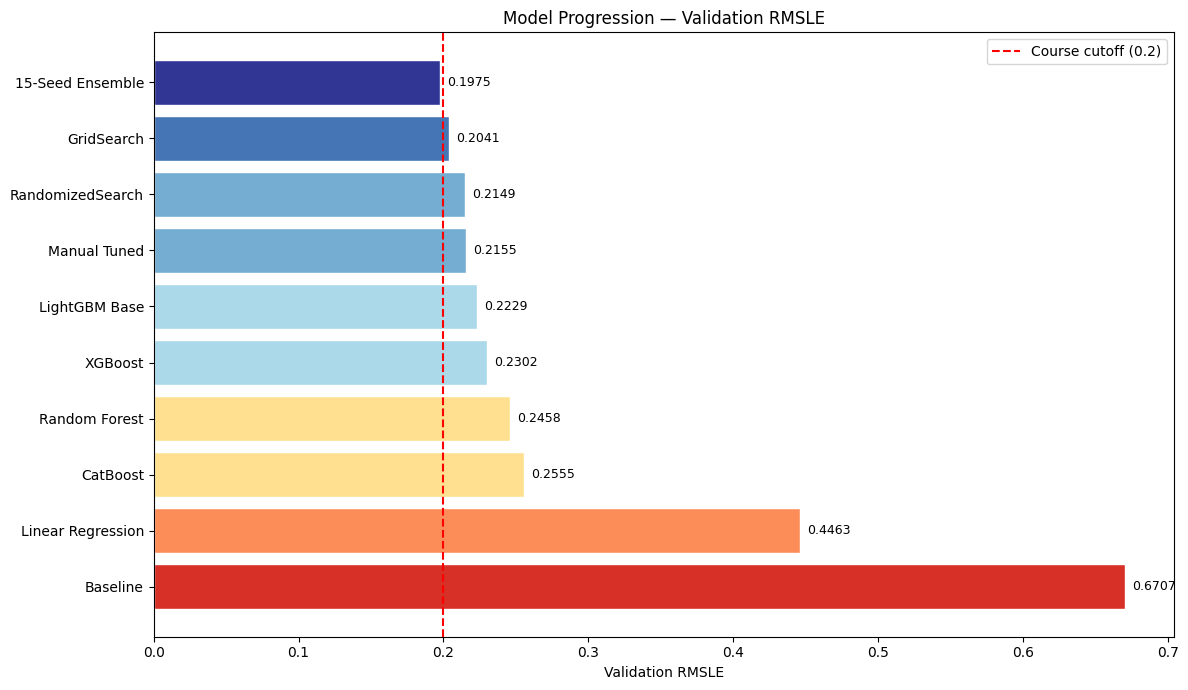

In [33]:
# Model Comparison Plot
models = [
    'Baseline',
    'Linear Regression', 
    'CatBoost',
    'Random Forest',
    'XGBoost',
    'LightGBM Base',
    'Manual Tuned',
    'RandomizedSearch',
    'GridSearch',
    '15-Seed Ensemble'
]

scores = [
    0.6707,
    0.4463,
    0.2555,
    0.2458,
    0.2302,
    0.2229,
    0.2155,
    0.2149,
    0.2041,
    0.1975
]

colors = [
    '#d73027',  
    '#fc8d59',  
    '#fee090',  
    '#fee090',  
    '#abd9e9', 
    '#abd9e9',  
    '#74add1',  
    '#74add1',  
    '#4575b4',  
    '#313695',  
]

plt.figure(figsize=(12, 7))
bars = plt.barh(models, scores, color=colors, edgecolor='white')


for bar, score in zip(bars, scores):
    plt.text(
        bar.get_width() + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{score:.4f}',
        va='center',
        fontsize=9
    )


plt.axvline(x=0.2, color='red', linestyle='--', linewidth=1.5,
            label='Course cutoff (0.2)')

plt.xlabel('Validation RMSLE')
plt.title('Model Progression — Validation RMSLE')
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# Final submission 
test_pred_final = np.expm1(ensemble_test_pred)

# Sanity checks — verify predictions are in plausible price range
print(f"Prediction range  : ${test_pred_final.min():,.0f} — ${test_pred_final.max():,.0f}")
print(f"Prediction median : ${np.median(test_pred_final):,.0f}")
print(f"Prediction mean   : ${np.mean(test_pred_final):,.0f}")

assert test_pred_final.min() > 0, "Negative predictions detected"
assert test_pred_final.max() < 500000, "Unreasonably high predictions detected"
print("Sanity checks passed.")

submission = pd.DataFrame({
    'TransactionID': test_ids,
    'TargetValue'  : test_pred_final
})

print(f"\nSubmission shape: {submission.shape}")
print(submission.head(10))

submission.to_csv('submission.csv', index=False)
print("\nsubmission.csv saved successfully.")
print(f"\nFinal Validation RMSLE : {seed_ensemble_score:.4f}")

Prediction range  : $7,231 — $141,562
Prediction median : $34,529
Prediction mean   : $40,813
Sanity checks passed.

Submission shape: (15000, 2)
   TransactionID   TargetValue
0        1139307  57061.363346
1        1139419  74733.570279
2        1139482  31905.922900
3        1139522  19633.108626
4        1139684  10844.489089
5        1139773  27937.661552
6        1139779  19324.218869
7        1139793  45958.859644
8        1139814  71708.514269
9        1139839  14981.075349

submission.csv saved successfully.

Final Validation RMSLE : 0.1975


## Milestone Answers


MILESTONE 1

In [ ]:
# train_raw.info();

In [ ]:
# train_raw.head(10)

In [ ]:
# print(train_raw['TargetValue'].describe())

In [ ]:
# print(train_raw['ManufactureYear'].mode())

In [ ]:
# print(train_raw['Spec_BaseClass'].describe())

In [ ]:
# corr = train_raw[['TargetValue', 'OperationalHoursMeter']].corr()
# print(corr)

In [ ]:
# print(train_raw['FunctionalClassification'].value_counts().head(10))

MILESTONE 2

In [ ]:
# # Q1 — Most frequent AssetAge
# most_freq_age = train_df['AssetAge'].value_counts().idxmax()
# most_freq_count = train_df['AssetAge'].value_counts().max()
# print(f"Most frequent AssetAge: {most_freq_age} (count: {most_freq_count})")

In [ ]:
# # Q2 — Quarter with highest average TargetValue
# quarter_avg = train_df.groupby('TransactionQuarter')['TargetValue'].mean().round(2)
# print("\nAvg TargetValue per Quarter:")
# print(quarter_avg)
# print(f"\nHighest: Q{quarter_avg.idxmax()} with ${quarter_avg.max():,.2f}")

In [ ]:
# # Q3 — Maximum DescriptorLength
# print(f"\nMax DescriptorLength: {train_df['DescriptorLength'].max()}")

In [ ]:
# # Q4 — Records with HasOperationalHours = 1
# print(f"\nRecords with HasOperationalHours=1: {(train_df['HasOperationalHours'] == 1).sum():,}")

In [ ]:
# # Q5 — Percentage with variant info
# pct_variant = (train_df['HasVariantModifier'] == 1).mean() * 100
# print(f"\n% records with variant info: {pct_variant:.2f}%")

In [ ]:
# # Q6 — Mean of ManufactureYear
# print(f"\nMean of ManufactureYear: {train_df['ManufactureYear'].mean():.2f}")

In [ ]:
# ohe_prefixes = ['RegionCode_', 'CabinType_', 'UtilizationTier_']
# ohe_created = [col for col in train_df.columns if any(col.startswith(p) for p in ohe_prefixes)]
# print(f"Number of OHE columns created: {len(ohe_created)}")
# print(ohe_created)

In [ ]:
# specific_cols = ['ManufactureYear', 'OperationalHoursMeter', 'AssetID', 'ProductConfigID', 'TargetValue']

# corr_with_target = train_df[specific_cols].corr()['TargetValue'].drop('TargetValue').abs().sort_values(ascending=False)
# print(corr_with_target.round(4))
# print(f"\nHighest absolute correlation with TargetValue: '{corr_with_target.idxmax()}' ({corr_with_target.max():.4f})")

In [ ]:
# # ── Quiz: StandardScaler on specific columns (isolated — does NOT affect main models) ──
# from sklearn.preprocessing import StandardScaler
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score

# # Work on a separate copy — never modify train_df
# quiz_df = train_df.copy()

# scale_cols = ['ManufactureYear', 'OperationalHoursMeter', 'AssetAge']

# # Impute with mean as instructed
# for col in scale_cols:
#     quiz_df[col] = quiz_df[col].fillna(quiz_df[col].mean())

# X_quiz = quiz_df.drop(columns=['TargetValue'])
# y_quiz = quiz_df['TargetValue']

# X_quiz_train, X_quiz_val, y_quiz_train, y_quiz_val = train_test_split(
#     X_quiz, y_quiz, test_size=0.2, random_state=42
# )

# scaler = StandardScaler()
# X_quiz_train[scale_cols] = scaler.fit_transform(X_quiz_train[scale_cols])
# X_quiz_val[scale_cols]   = scaler.transform(X_quiz_val[scale_cols])

# print(f"X_train shape: {X_quiz_train.shape}")
# print(f"X_val shape  : {X_quiz_val.shape}")

# # Linear Regression on ManufactureYear + AssetAge only
# lr_quiz = LinearRegression()
# lr_quiz.fit(X_quiz_train[['ManufactureYear', 'AssetAge']], y_quiz_train)
# lr_quiz_pred = lr_quiz.predict(X_quiz_val[['ManufactureYear', 'AssetAge']])
# print(f"\nR² Score on Validation Set: {r2_score(y_quiz_val, lr_quiz_pred):.4f}")

MILESTONE 3

In [ ]:
# # Work on a copy — never modify train_raw
# df_m3 = train_raw.copy()

# # Fill missing values in CabinType with "Missing"
# df_m3['CabinType'] = df_m3['CabinType'].fillna('Missing')

# # Count rows with "Missing"
# missing_count = (df_m3['CabinType'] == 'Missing').sum()
# print(f"Rows with 'Missing' in CabinType: {missing_count:,}")

In [ ]:
# # Parse TransactionDate to extract SaleYear
# df_m3['TransactionDate'] = pd.to_datetime(df_m3['TransactionDate'])
# df_m3['SaleYear'] = df_m3['TransactionDate'].dt.year

# # Replace BOTH 1000 and 1001 with NaN
# df_m3['ManufactureYear'] = df_m3['ManufactureYear'].replace({1000: np.nan, 1001: np.nan})

# # Calculate AssetAge
# df_m3['AssetAge'] = df_m3['SaleYear'] - df_m3['ManufactureYear']

# # Median AssetAge
# print(f"Median AssetAge: {df_m3['AssetAge'].median()}")

In [ ]:
# # Fill OperationalHoursMeter nulls with median first
# df_m3['OperationalHoursMeter'] = df_m3['OperationalHoursMeter'].fillna(df_m3['OperationalHoursMeter'].median())

# # Create HoursPerYear — divide by AssetAge (add 0 check to avoid division by zero)
# df_m3['HoursPerYear'] = df_m3['OperationalHoursMeter'] / df_m3['AssetAge']

# # Median ignoring inf and NaN
# median_hpy = df_m3['HoursPerYear'].replace([np.inf, -np.inf], np.nan).dropna().median()
# print(f"Median HoursPerYear: {median_hpy:.4f}")

In [ ]:
# # Calculate missing percentage for each column
# missing_pct = df_m3.isnull().sum() / len(df_m3) * 100

# # Columns with more than 80% missing
# cols_to_drop = missing_pct[missing_pct > 80].index.tolist()

# print(f"Columns with > 80% missing: {len(cols_to_drop)}")
# print(cols_to_drop)

In [ ]:
# # TransactionDate already parsed in df_m3 — SaleYear already created
# print(f"Most frequent SaleYear (mode): {df_m3['SaleYear'].mode()[0]}")

In [ ]:
# from sklearn.model_selection import train_test_split

# X_m3 = df_m3.drop(columns=['TargetValue'])
# y_m3 = df_m3['TargetValue']

# X_m3_train, X_m3_val, y_m3_train, y_m3_val = train_test_split(
#     X_m3, y_m3, test_size=0.2, random_state=42
# )

# print(f"X_train rows: {X_m3_train.shape[0]:,}")

In [ ]:
# y_log = np.log1p(df_m3['TargetValue'])
# print(f"Standard deviation after log1p: {y_log.std():.4f}")

In [ ]:
# from sklearn.preprocessing import OrdinalEncoder

# # Work on a temp copy of the column
# oe = OrdinalEncoder()
# df_m3['UtilizationTier_encoded'] = oe.fit_transform(df_m3[['UtilizationTier']])

# print(f"Unique integer values: {df_m3['UtilizationTier_encoded'].nunique()}")
# print(f"Values: {sorted(df_m3['UtilizationTier_encoded'].unique())}")
# print(f"Categories mapped: {oe.categories_}")

MILESTONE 4

In [ ]:
# from sklearn.model_selection import train_test_split
# import numpy as np

# # Setup — use specified columns only
# cols = ['TargetValue', 'UtilizationTier', 'DrivetrainType', 'CabinType', 
#         'AssetScaleFactor', 'ManufactureYear', 'OperationalHoursMeter']
# df_m4 = train_raw[cols].copy()

# # Fill missing UtilizationTier
# df_m4['UtilizationTier'] = df_m4['UtilizationTier'].fillna('Unknown')

# # Create PriceBand
# df_m4['PriceBand'] = pd.qcut(df_m4['TargetValue'], q=5, labels=False)

# X_m4 = df_m4.drop(columns=['TargetValue'])
# y_m4 = df_m4['TargetValue']

# # Part A — Stratified split
# X_train_A, X_val_A, y_train_A, y_val_A = train_test_split(
#     X_m4, y_m4, test_size=0.3, random_state=42,
#     stratify=df_m4['PriceBand']
# )
# counts_A = X_val_A['PriceBand'].value_counts().sort_index().values
# print(f"Stratified val PriceBand counts   : {counts_A}")

# # Part B — Non-stratified split
# X_train_B, X_val_B, y_train_B, y_val_B = train_test_split(
#     X_m4, y_m4, test_size=0.3, random_state=42,
#     stratify=None
# )
# counts_B = X_val_B['PriceBand'].value_counts().sort_index().values
# print(f"Non-stratified val PriceBand counts: {counts_B}")

# # Part C — Max absolute difference in proportions
# total_val = len(X_val_A)
# prop_A = counts_A / total_val
# prop_B = counts_B / total_val
# max_diff = np.abs(prop_A - prop_B).max()
# print(f"\nMax absolute difference in proportions: {max_diff:.4f}")

In [ ]:
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.compose import ColumnTransformer

# # Use stratified split from Q1
# X_train_m4 = X_train_A.copy()
# X_valid_m4 = X_val_A.copy()

# # Drop PriceBand — not a feature
# X_train_m4 = X_train_m4.drop(columns=['PriceBand'])
# X_valid_m4 = X_valid_m4.drop(columns=['PriceBand'])

# # Define column groups
# cat_cols = ['UtilizationTier', 'DrivetrainType', 'CabinType', 'AssetScaleFactor']
# num_cols = ['ManufactureYear', 'OperationalHoursMeter']

# # Categorical pipeline
# cat_pipeline = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=True))
# ])

# # Numerical pipeline
# num_pipeline = Pipeline([
#     ('imputer', SimpleImputer(strategy='mean')),
#     ('scaler',  StandardScaler())
# ])

# # ColumnTransformer
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('cat', cat_pipeline, cat_cols),
#         ('num', num_pipeline, num_cols)
#     ],
#     remainder='drop'
# )

# # Fit on train only, transform both
# X_train_proc = preprocessor.fit_transform(X_train_m4)
# X_valid_proc  = preprocessor.transform(X_valid_m4)

# # Sum of all values in X_train_proc
# import scipy.sparse as sp
# if sp.issparse(X_train_proc):
#     total_sum = X_train_proc.sum()
# else:
#     total_sum = X_train_proc.sum()

# print(f"Shape of X_train_proc : {X_train_proc.shape}")
# print(f"Shape of X_valid_proc : {X_valid_proc.shape}")
# print(f"Sum of all values in X_train_proc: {total_sum:.3f}")

In [ ]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.model_selection import RandomizedSearchCV

# param_dist_m4 = {
#     'n_estimators': [50, 100, 200],
#     'max_depth'   : [5, 10, 15]
# }

# rf_m4 = RandomForestRegressor(random_state=42)

# random_search_m4 = RandomizedSearchCV(
#     estimator=rf_m4,
#     param_distributions=param_dist_m4,
#     n_iter=5,
#     cv=3,
#     random_state=42,
#     n_jobs=-1
# )

# random_search_m4.fit(X_train_proc, y_train_A)

# print(f"Best n_estimators: {random_search_m4.best_params_['n_estimators']}")
# print(f"Best max_depth   : {random_search_m4.best_params_['max_depth']}")
# print(f"Best params      : {random_search_m4.best_params_}")

In [ ]:
# from sklearn.ensemble import AdaBoostRegressor

# ada = AdaBoostRegressor(n_estimators=50, random_state=42)
# ada.fit(X_train_proc, y_train_A)

# variance = np.var(ada.estimator_errors_)
# print(f"Variance of estimator_errors_: {variance:.4f}")

In [ ]:
# from sklearn.ensemble import RandomForestRegressor

# rf_m4_q5 = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
# rf_m4_q5.fit(X_train_proc, y_train_A)

# importances = rf_m4_q5.feature_importances_
# max_index = np.argmin(np.where(importances == importances.max(), 
#                                 np.arange(len(importances)), 
#                                 len(importances)))
# print(f"Index of max importance feature: {max_index}")
# print(f"Max importance value           : {importances[max_index]:.4f}")

In [ ]:
# # Get N from X_train_proc
# N = X_train_proc.shape[1]
# print(f"N (input features): {N}")

# # Architecture: N → 128 → 64 → 32 → 1
# # Weights only (no biases)
# w1 = N   * 128
# w2 = 128 * 64
# w3 = 64  * 32
# w4 = 32  * 1

# total_weights = w1 + w2 + w3 + w4
# print(f"Layer 1 weights (N→128)  : {w1}")
# print(f"Layer 2 weights (128→64) : {w2}")
# print(f"Layer 3 weights (64→32)  : {w3}")
# print(f"Layer 4 weights (32→1)   : {w4}")
# print(f"Total connection weights : {total_weights}")

In [ ]:
# from sklearn.neural_network import MLPRegressor

# mlp = MLPRegressor(
#     hidden_layer_sizes=(128, 64, 32),
#     activation='relu',
#     solver='adam',
#     max_iter=5,
#     batch_size=32,
#     random_state=42
# )

# mlp.fit(X_train_proc, y_train_A)

# print(f"Training loss after 5 iterations: {mlp.loss_:.4f}")

In [ ]:
# from sklearn.neural_network import MLPRegressor
# from sklearn.metrics import mean_absolute_error

# # Model A — light regularization
# mlp_A = MLPRegressor(
#     hidden_layer_sizes=(100,),
#     max_iter=5,
#     alpha=0.0001,
#     random_state=42
# )
# mlp_A.fit(X_train_proc, y_train_A)
# mae_A = mean_absolute_error(y_train_A, mlp_A.predict(X_train_proc))
# print(f"Model A (alpha=0.0001) MAE: {mae_A:.4f}")

# # Model B — strong regularization
# mlp_B = MLPRegressor(
#     hidden_layer_sizes=(100,),
#     max_iter=5,
#     alpha=1.0,
#     random_state=42
# )
# mlp_B.fit(X_train_proc, y_train_A)
# mae_B = mean_absolute_error(y_train_A, mlp_B.predict(X_train_proc))
# print(f"Model B (alpha=1.0)    MAE: {mae_B:.4f}")

# print(f"\nAbsolute difference in MAE: {abs(mae_A - mae_B):.4f}")

In [ ]:
# from sklearn.metrics import mean_absolute_error

# val_pred_mlp = mlp.predict(X_valid_proc)
# mae_val = mean_absolute_error(y_val_A, val_pred_mlp)
# print(f"Validation MAE (Q7 MLP): {mae_val:.4f}")

MILESTONE 5

In [ ]:
# # Setup — fresh copy for milestone 5
# df_m5 = train_raw.copy()

# # Parse TransactionDate
# df_m5['TransactionDate'] = pd.to_datetime(df_m5['TransactionDate'])

# # Create all derived features
# df_m5['TransactionYear']    = df_m5['TransactionDate'].dt.year
# df_m5['TransactionMonth']   = df_m5['TransactionDate'].dt.month
# df_m5['TransactionQuarter'] = df_m5['TransactionDate'].dt.quarter
# df_m5['ManufactureDecade']  = (df_m5['ManufactureYear'] // 10) * 10
# df_m5['SpecificationComplexity'] = df_m5['Spec_FullDescriptor'].apply(
#     lambda x: len(str(x).split())
# )

# print("All features created.")
# print(df_m5[['TransactionYear','TransactionMonth','TransactionQuarter',
#              'ManufactureDecade','SpecificationComplexity']].head())

In [ ]:
# # Q1 — ManufactureDecade with highest average TargetValue
# decade_avg = df_m5.groupby('ManufactureDecade')['TargetValue'].mean()
# print(f"ManufactureDecade with highest avg TargetValue: {decade_avg.idxmax()}")
# print(f"Average TargetValue: ${decade_avg.max():,.2f}")

In [ ]:
# # Q2 — Maximum SpecificationComplexity
# print(f"Maximum SpecificationComplexity: {df_m5['SpecificationComplexity'].max()}")

In [ ]:
# # Define feature sets
# cat_features = [
#     'DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
#     'AssetScaleFactor', 'RegionCode', 'InventoryGroupCategory',
#     'InventoryGroupDescription'
# ]

# # All numerical except TransactionID and AssetID
# num_features = [col for col in df_m5.select_dtypes(include='number').columns
#                 if col not in ['TransactionID', 'AssetID', 'TargetValue']]

# print(f"Categorical features : {len(cat_features)}")
# print(f"Numerical features   : {len(num_features)}")
# print(f"Numerical cols       : {num_features}")

# # Create new training data
# selected_cols = cat_features + num_features + ['TargetValue']
# df_m5_selected = df_m5[selected_cols].copy()

# total_features = len(cat_features) + len(num_features)
# print(f"\nTotal features in Training Data: {total_features}")

In [ ]:
# from sklearn.model_selection import train_test_split

# X_m5 = df_m5_selected.drop(columns=['TargetValue'])
# y_m5 = df_m5_selected['TargetValue']

# X_m5_train, X_m5_val, y_m5_train, y_m5_val = train_test_split(
#     X_m5, y_m5, test_size=0.2, random_state=42
# )

# print(f"X_m5_train shape: {X_m5_train.shape}")
# print(f"X_m5_val shape  : {X_m5_val.shape}")

In [ ]:
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
# from sklearn.compose import ColumnTransformer

# # Numerical pipeline
# num_pipeline_m5 = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler',  StandardScaler())
# ])

# # Categorical pipeline
# cat_pipeline_m5 = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=True))
# ])

# # ColumnTransformer
# preprocessor_m5 = ColumnTransformer(
#     transformers=[
#         ('num', num_pipeline_m5, num_features),
#         ('cat', cat_pipeline_m5, cat_features)
#     ],
#     remainder='drop'
# )

# # Fit on train only, transform both
# X_m5_train_proc = preprocessor_m5.fit_transform(X_m5_train)
# X_m5_val_proc   = preprocessor_m5.transform(X_m5_val)

# print(f"X_m5_train_proc shape: {X_m5_train_proc.shape}")
# print(f"X_m5_val_proc shape  : {X_m5_val_proc.shape}")

In [ ]:
# # Check exactly what's being selected
# print(f"Numerical features ({len(num_features)}): {num_features}")
# print(f"Categorical features ({len(cat_features)}): {cat_features}")

# # Try with just label encoding instead of OHE for categoricals
# from sklearn.preprocessing import OrdinalEncoder

# cat_pipeline_ord = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('ord',     OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
# ])

# preprocessor_ord = ColumnTransformer(
#     transformers=[
#         ('num', num_pipeline_m5, num_features),
#         ('cat', cat_pipeline_ord, cat_features)
#     ],
#     remainder='drop'
# )

# X_m5_train_ord = preprocessor_ord.fit_transform(X_m5_train)
# print(f"Shape with OrdinalEncoder: {X_m5_train_ord.shape}")

# # Also try with no encoding at all — just imputation
# from sklearn.preprocessing import LabelEncoder

# cat_pipeline_imp = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent'))
# ])

# preprocessor_imp = ColumnTransformer(
#     transformers=[
#         ('num', num_pipeline_m5, num_features),
#         ('cat', cat_pipeline_imp, cat_features)
#     ],
#     remainder='drop'
# )

# X_m5_train_imp = preprocessor_imp.fit_transform(X_m5_train)
# print(f"Shape with imputation only: {X_m5_train_imp.shape}")

In [ ]:
# from sklearn.feature_selection import SelectKBest, f_regression
# import scipy.sparse as sp

# # Apply SelectKBest on training set
# selector = SelectKBest(score_func=f_regression, k=100)
# X_m5_train_kbest = selector.fit_transform(X_m5_train_proc, y_m5_train)
# X_m5_val_kbest   = selector.transform(X_m5_val_proc)

# # Get feature names
# num_feature_names = num_features
# cat_feature_names = preprocessor_m5.named_transformers_['cat']\
#                     .named_steps['ohe'].get_feature_names_out(cat_features).tolist()
# all_feature_names = num_feature_names + cat_feature_names

# # F-scores and selection mask
# f_scores = selector.scores_
# mask     = selector.get_support()

# selected_features = [all_feature_names[i] for i in range(len(all_feature_names)) if mask[i]]
# removed_features  = [all_feature_names[i] for i in range(len(all_feature_names)) if not mask[i]]

# print(f"Total features before : {len(all_feature_names)}")
# print(f"Selected features     : {len(selected_features)}")
# print(f"Removed features      : {len(removed_features)}")
# print(f"\nShape after SelectKBest — train: {X_m5_train_kbest.shape}")

In [ ]:
# # Q5 — Feature with highest F-score
# best_idx  = np.argmax(f_scores)
# print(f"Highest F-score feature : '{all_feature_names[best_idx]}'")
# print(f"F-score                 : {f_scores[best_idx]:.4f}")

In [ ]:
# # Check the 3 options with correct naming
# options_correct = ['AssetScaleFactor_Mini', 'UtilizationTier_Low', 'RegionCode_Oklahoma']

# for feat in options_correct:
#     if feat in all_feature_names:
#         idx = all_feature_names.index(feat)
#         is_selected = mask[idx]
#         print(f"{feat}")
#         print(f"  F-score   : {f_scores[idx]:.4f}")
#         print(f"  Selected  : {is_selected}")

# # Lowest F-score among selected
# selected_options = [(f, f_scores[all_feature_names.index(f)])
#                     for f in options_correct
#                     if f in all_feature_names and mask[all_feature_names.index(f)]]
# if selected_options:
#     lowest = min(selected_options, key=lambda x: x[1])
#     print(f"\nAnswer: '{lowest[0]}' with F-score {lowest[1]:.4f}")

In [ ]:
# # Q7 — Features removed by SelectKBest
# print(f"Removed features ({len(removed_features)} total):")
# for f in removed_features:
#     print(f"  {f}")

In [ ]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_absolute_error

# rf_baseline = RandomForestRegressor(random_state=42)
# rf_baseline.fit(X_m5_train_kbest, y_m5_train)

# val_pred_rf = rf_baseline.predict(X_m5_val_kbest)
# mae_rf = mean_absolute_error(y_m5_val, val_pred_rf)
# print(f"Validation MAE: {mae_rf:.2f}")

In [ ]:
# from sklearn.metrics import mean_squared_error

# rmse_rf = np.sqrt(mean_squared_error(y_m5_val, val_pred_rf))
# print(f"Validation RMSE: {rmse_rf:.2f}")

In [ ]:
# from sklearn.model_selection import RandomizedSearchCV
# from sklearn.ensemble import RandomForestRegressor

# param_dist_m5 = {
#     'n_estimators': [100, 200],
#     'max_depth'   : [10, None],
#     'max_features': ['sqrt']
# }

# rf_m5 = RandomForestRegressor(random_state=42)

# random_search_m5 = RandomizedSearchCV(
#     estimator=rf_m5,
#     param_distributions=param_dist_m5,
#     n_iter=4,
#     scoring='neg_root_mean_squared_error',
#     cv=3,
#     random_state=42,
#     n_jobs=-1
# )

# random_search_m5.fit(X_m5_train_kbest, y_m5_train)

# print(f"Best params      : {random_search_m5.best_params_}")
# print(f"Best n_estimators: {random_search_m5.best_params_['n_estimators']}")
# print(f"Best CV RMSE     : {-random_search_m5.best_score_:.2f}")

In [ ]:
# best_rf_m5 = random_search_m5.best_estimator_
# val_pred_tuned = best_rf_m5.predict(X_m5_val_kbest)
# mae_tuned = mean_absolute_error(y_m5_val, val_pred_tuned)
# print(f"Validation MAE (tuned RF): {mae_tuned:.2f}")

In [ ]:
# rmse_tuned = np.sqrt(mean_squared_error(y_m5_val, val_pred_tuned))
# print(f"Validation RMSE (tuned RF): {rmse_tuned:.2f}")

In [ ]:
# from sklearn.datasets import load_diabetes

# d = load_diabetes()
# features = d.feature_names
# target = d.target

# print("Feature : ", features)
# print("Target : ",target)